In [1]:
## same as the harris corner detector except for the fact that the response function is now R = min(lambda1, lambda2)
## instead of whatever the heck harris suggested

## shi tomasi states that if the lambda (the eigenvalue/s) is more than a certain threshold value, the region is a / has a corner

In [15]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [16]:
img = cv2.imread("wallimage.jpg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
img = img.astype(np.float32)
img = cv2.resize(img, (400, 800))
# output_img = np.zeros_like(img, dtype=np.float32)
output_img = img.copy()

In [17]:
img.shape

(800, 400)

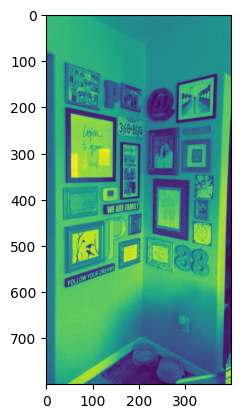

In [18]:
plt.imshow(img)

In [ ]:
kernel_dim = 3
l = []
for i in range(kernel_dim//2, img.shape[0]-kernel_dim//2):
    for j in range(kernel_dim//2, img.shape[1]-kernel_dim//2):
        operand_img = img[i-kernel_dim//2:i+kernel_dim//2+1, j-kernel_dim//2: j+kernel_dim//2+1]
        Ix = (operand_img[0, 1] - operand_img[0, 0]) + (operand_img[1, 1] - operand_img[1, 0]) + (operand_img[2, 1] - operand_img[2, 0])
        Iy = (operand_img[1, 0] - operand_img[0, 0]) + (operand_img[1, 1] - operand_img[0, 1]) + (operand_img[1, 2] - operand_img[0, 2])
        
        M = np.array([[Ix**2, Ix*Iy], [Ix*Iy, Iy**2]])
        eigenvalues = np.linalg.eigvals(M)
        min_eigenvalue = np.min(eigenvalues)
        l.append(min_eigenvalue)
        if min_eigenvalue > .01 * 0.00412136: # this condition is basically 1% of the max eigenvalue; the 1% is called the quality value
            output_img = cv2.circle(output_img, (j, i), 1, (0, 0, 0), -1)


In [ ]:
max(l)

In [ ]:
plt.imshow(output_img)